In [1]:
from cmath import inf
from unittest.mock import inplace

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from unicodedata import numeric

warnings.filterwarnings("ignore")



In [2]:
df = pd.read_csv("insurance.csv")

In [3]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


EDA


In [4]:
df.shape

(1338, 7)

In [5]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [9]:
df.isnull()

,age,sex,bmi,children,smoker,region,charges
0,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...
1333,False,False,False,False,False,False,False
1334,False,False,False,False,False,False,False
1335,False,False,False,False,False,False,False
1336,False,False,False,False,False,False,False


In [10]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [11]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

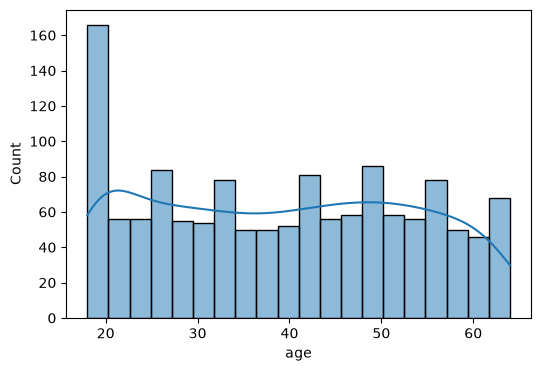

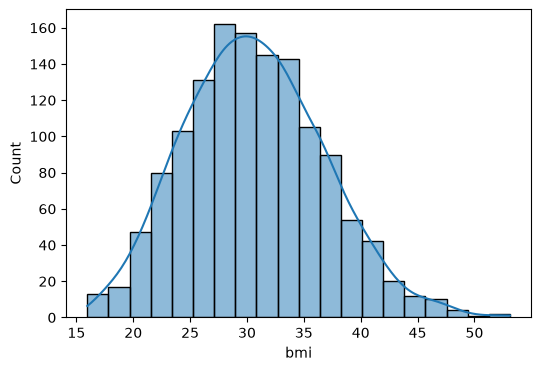

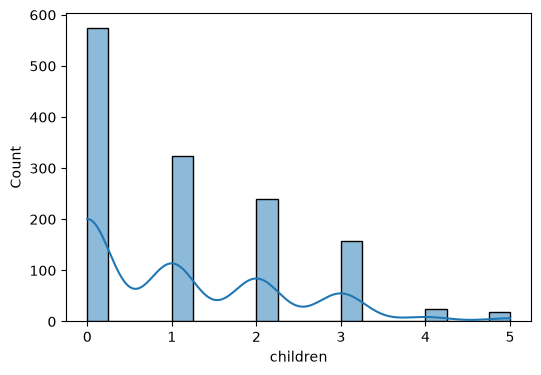

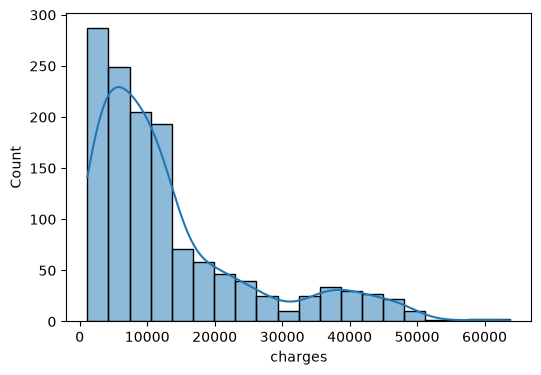

In [12]:
numeric_col = ['age','bmi','children','charges']
for col in numeric_col:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col],kde=True,bins=20)


<Axes: xlabel='children', ylabel='count'>

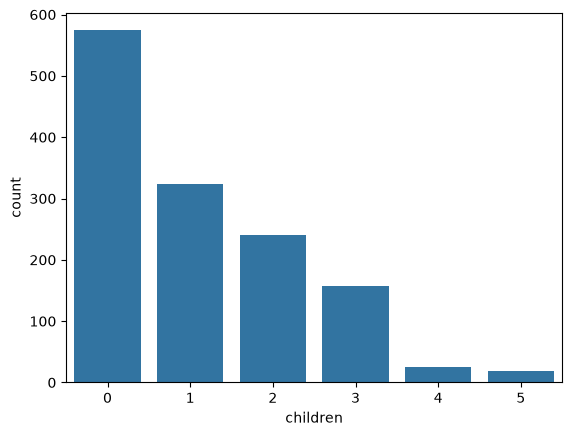

In [13]:
sns.countplot(x=df['children'])


<Axes: xlabel='sex', ylabel='count'>

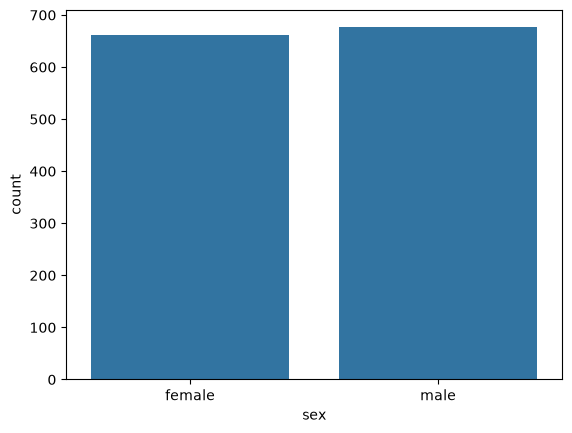

In [14]:
sns.countplot(x=df['sex'])

<Axes: xlabel='smoker', ylabel='count'>

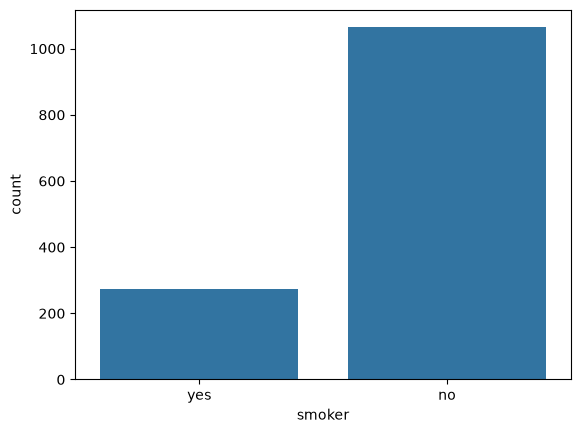

In [15]:
sns.countplot(x=df['smoker'])

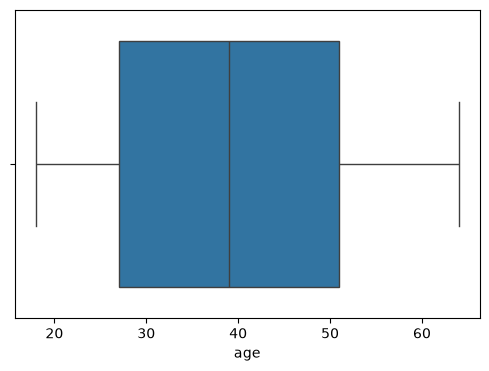

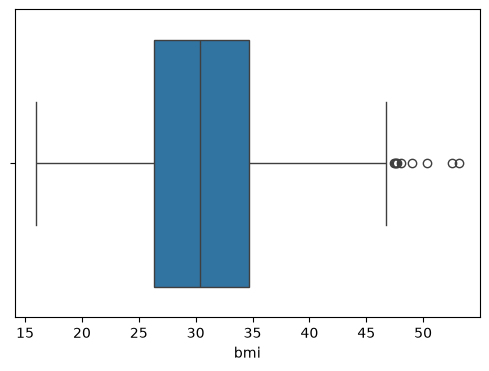

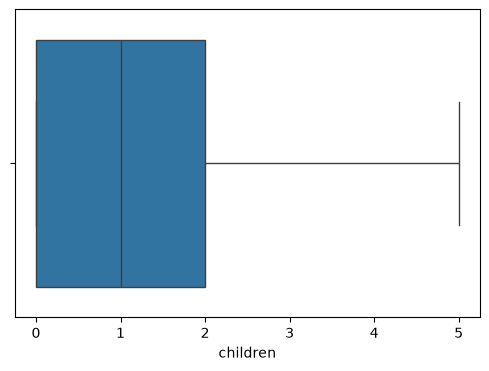

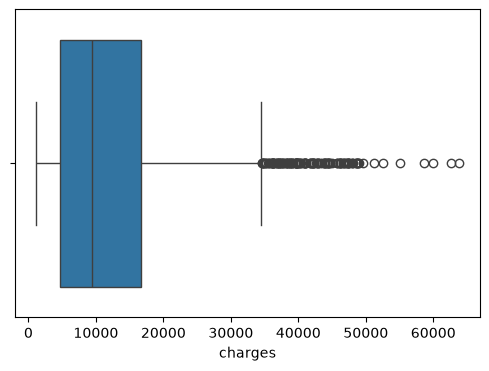

In [16]:
for col in numeric_col:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])


Heatmap


<Axes: >

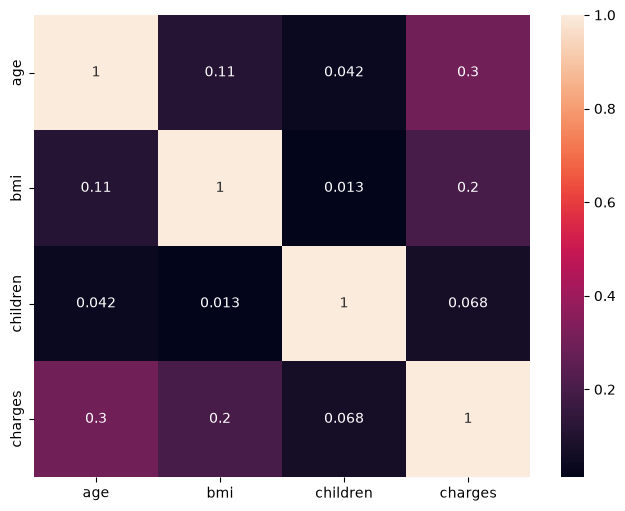

In [17]:
plt.figure(figsize = (8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True )

Data Cleaning and Pre-processing


In [18]:
df_cleaned =df.copy()
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [19]:
df_cleaned.shape

(1338, 7)

In [20]:
df_cleaned.drop_duplicates(inplace=True)

In [21]:
df_cleaned.shape

(1337, 7)

In [22]:
df_cleaned.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [23]:
df_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [24]:
df_cleaned["smoker"].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [25]:
df_cleaned["region"].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [26]:
df_cleaned["sex"] = df_cleaned["sex"].map({"male":0,"female":1})

In [27]:
df_cleaned.rename(columns={"sex": "is_felmale"},inplace=True)

In [28]:
df_cleaned["smoker"] = df_cleaned["smoker"].map({"yes":0,"no":1})

In [29]:
df_cleaned.rename(columns={"smoker": "is_chainsmoker"},inplace=True)



In [30]:
df_cleaned

,age,is_felmale,bmi,children,is_chainsmoker,region,charges
0,19,1,27.900,0,0,southwest,16884.92400
1,18,0,33.770,1,1,southeast,1725.55230
2,28,0,33.000,3,1,southeast,4449.46200
3,33,0,22.705,0,1,northwest,21984.47061
4,32,0,28.880,0,1,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,1,northwest,10600.54830
1334,18,1,31.920,0,1,northeast,2205.98080
1335,18,1,36.850,0,1,southeast,1629.83350
1336,21,1,25.800,0,1,southwest,2007.94500


In [31]:
df_cleaned = pd.get_dummies(
    df_cleaned,
    columns=["region"],
    drop_first=False,
     dtype=int
)

In [32]:
df_cleaned.head()

,age,is_felmale,bmi,children,is_chainsmoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,0,16884.92400,0,0,0,1
1,18,0,33.770,1,1,1725.55230,0,0,1,0
2,28,0,33.000,3,1,4449.46200,0,0,1,0
3,33,0,22.705,0,1,21984.47061,0,1,0,0
4,32,0,28.880,0,1,3866.85520,0,1,0,0


Feature Engg. and Extraction

step1:- plot the histplot for bmi


<Axes: xlabel='bmi', ylabel='Count'>

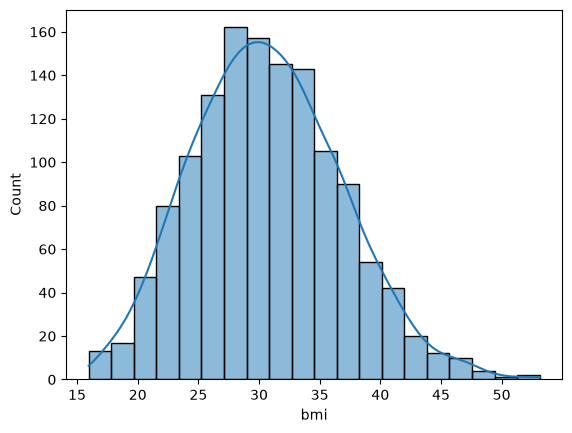

In [33]:
sns.histplot(df['bmi'],kde=True,bins=20)

step2:- Creating the bins

In [34]:
df_cleaned['bmi_category']= pd.cut(
    df_cleaned['bmi'],
    bins=[0,18.5,24.9,29.9,float('inf')],
  labels=['underweight','Normal','Overweight','Obese'])


In [35]:
df_cleaned.head()

,age,is_felmale,bmi,children,is_chainsmoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27.900,0,0,16884.92400,0,0,0,1,Overweight
1,18,0,33.770,1,1,1725.55230,0,0,1,0,Obese
2,28,0,33.000,3,1,4449.46200,0,0,1,0,Obese
3,33,0,22.705,0,1,21984.47061,0,1,0,0,Normal
4,32,0,28.880,0,1,3866.85520,0,1,0,0,Overweight


Step3:- Now the bmi catagory is 'obj' or 'str' apply onehot encoding to change this in 0&1 form

In [36]:
df_cleaned = pd.get_dummies(
    df_cleaned,
    columns=["bmi_category"],
    drop_first=False,
     dtype=int
)

In [37]:
df_cleaned.head()

,age,is_felmale,bmi,children,is_chainsmoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27.900,0,0,16884.92400,0,0,0,1,0,0,1,0
1,18,0,33.770,1,1,1725.55230,0,0,1,0,0,0,0,1
2,28,0,33.000,3,1,4449.46200,0,0,1,0,0,0,0,1
3,33,0,22.705,0,1,21984.47061,0,1,0,0,0,1,0,0
4,32,0,28.880,0,1,3866.85520,0,1,0,0,0,0,1,0


Scaling

In [38]:
X = df_cleaned.drop('charges', axis=1)
y = df_cleaned['charges']

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [40]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [41]:
df_cleaned.head(
    
)

,age,is_felmale,bmi,children,is_chainsmoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27.900,0,0,16884.92400,0,0,0,1,0,0,1,0
1,18,0,33.770,1,1,1725.55230,0,0,1,0,0,0,0,1
2,28,0,33.000,3,1,4449.46200,0,0,1,0,0,0,0,1
3,33,0,22.705,0,1,21984.47061,0,1,0,0,0,1,0,0
4,32,0,28.880,0,1,3866.85520,0,1,0,0,0,0,1,0


In [42]:
from sklearn.preprocessing import StandardScaler

cols = ['age', 'bmi','is_chainsmoker','region_southeast']

X_train = X_train.copy()
X_test = X_test.copy()

scaler = StandardScaler()

X_train[cols] = scaler.fit_transform(X_train[cols])
X_test[cols] = scaler.transform(X_test[cols])

In [43]:
df_cleaned.head()

,age,is_felmale,bmi,children,is_chainsmoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27.900,0,0,16884.92400,0,0,0,1,0,0,1,0
1,18,0,33.770,1,1,1725.55230,0,0,1,0,0,0,0,1
2,28,0,33.000,3,1,4449.46200,0,0,1,0,0,0,0,1
3,33,0,22.705,0,1,21984.47061,0,1,0,0,0,1,0,0
4,32,0,28.880,0,1,3866.85520,0,1,0,0,0,0,1,0


In [44]:
df_cleaned.dtypes

age                           int64
is_felmale                    int64
bmi                         float64
children                      int64
is_chainsmoker                int64
charges                     float64
region_northeast              int64
region_northwest              int64
region_southeast              int64
region_southwest              int64
bmi_category_underweight      int64
bmi_category_Normal           int64
bmi_category_Overweight       int64
bmi_category_Obese            int64
dtype: object

In [45]:
import pandas as pd
from scipy.stats import chi2_contingency

# Copy your cleaned dataset
df = df_cleaned.copy()

# Convert continuous target 'charges' into categories
df['charges_bin'] = pd.qcut(
    df['charges'],
    q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

alpha = 0.05
results = []

# Exclude target columns
features = [
    col for col in df.columns
    if col not in ['charges', 'charges_bin']
]

for feature in features:

    data = df[[feature, 'charges_bin']].dropna().copy()

    # Convert continuous numerical features into categories
    if (pd.api.types.is_numeric_dtype(data[feature])
            and data[feature].nunique() > 10):
        data[feature] = pd.qcut(
            data[feature],
            q=4,
            duplicates='drop'
        )

    # Create contingency table
    table = pd.crosstab(data[feature], data['charges_bin'])

    if table.shape[0] < 2 or table.shape[1] < 2:
        results.append({
            'Feature': feature,
            'Chi2 Statistic': None,
            'P-Value': None,
            'Alpha': alpha,
            'Decision': 'Insufficient categories'
        })
        continue

    # Perform Chi-Square test
    chi2, p_value, dof, expected = chi2_contingency(table)

    # Compare p-value with alpha
    if p_value < alpha:
        decision = 'Keep feature'
    else:
        decision = 'Drop feature'

    # Store result
    results.append({
        'Feature': feature,
        'Chi2 Statistic': chi2,
        'P-Value': p_value,
        'Alpha': alpha,
        'Decision': decision
    })

# Convert results into DataFrame
chi2_results = pd.DataFrame(results)

print(chi2_results)

                     Feature  Chi2 Statistic        P-Value  Alpha  \
0                        age     1182.364611  7.775747e-249   0.05   
1                 is_felmale       10.258784   1.648974e-02   0.05   
2                        bmi       16.755859   5.267933e-02   0.05   
3                   children      138.659313   4.230749e-22   0.05   
4             is_chainsmoker      848.219178  1.507478e-183   0.05   
5           region_northeast        6.438442   9.212206e-02   0.05   
6           region_northwest        1.134240   7.688154e-01   0.05   
7           region_southeast       15.998167   1.134966e-03   0.05   
8           region_southwest        5.091893   1.651906e-01   0.05   
9   bmi_category_underweight        4.384749   2.228037e-01   0.05   
10       bmi_category_Normal        4.263673   2.343638e-01   0.05   
11   bmi_category_Overweight        4.201575   2.405042e-01   0.05   
12        bmi_category_Obese        7.654464   5.371967e-02   0.05   

        Decision  


In [46]:
from sklearn.linear_model import LinearRegression

# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

print("Model training completed")

Model training completed


In [47]:
# Make predictions
y_pred = model.predict(X_test)

print("Predicted values:")
print(y_pred[:10])

Predicted values:
[ 8165.93791076  5264.01712303 14492.93605754 32412.34632566
  8892.41139086 13251.93939913 30611.47884684   973.16907743
 11129.62557559 10122.658709  ]


In [48]:
#compare actual value and predicted value 
import pandas as pd

comparison = pd.DataFrame({
    "Actual Charges": y_test,
    "Predicted Charges": y_pred
})

print(comparison.head(10))


      Actual Charges  Predicted Charges
900       8688.85885        8165.937911
1064      5708.86700        5264.017123
1256     11436.73815       14492.936058
298      38746.35510       32412.346326
237       4463.20510        8892.411391
481       9304.70190       13251.939399
240      38511.62830       30611.478847
277       2150.46900         973.169077
415       7345.72660       11129.625576
707      10264.44210       10122.658709


In [49]:
comparison = pd.DataFrame({
    "Actual Charges": y_test,
    "Predicted Charges": y_pred
})

In [50]:
print(comparison.head(10))

      Actual Charges  Predicted Charges
900       8688.85885        8165.937911
1064      5708.86700        5264.017123
1256     11436.73815       14492.936058
298      38746.35510       32412.346326
237       4463.20510        8892.411391
481       9304.70190       13251.939399
240      38511.62830       30611.478847
277       2150.46900         973.169077
415       7345.72660       11129.625576
707      10264.44210       10122.658709


In [51]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MAE: 4340.6128527493765
MSE: 36250556.724953175
RMSE: 6020.84352270952
R2 Score: 0.8027245690414588


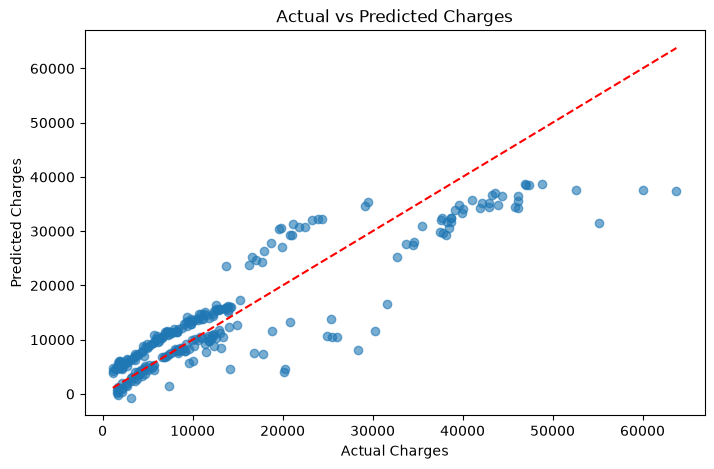

In [52]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Charges")
plt.show()


In [63]:

# Predict on one existing test record
sample = X_test.iloc[[6]]

prediction = model.predict(sample)

print("Predicted Insurance Charges:", prediction[0])
print("Actual Insurance Charges:", y_test.iloc[6])


Predicted Insurance Charges: 30611.478846839414
Actual Insurance Charges: 38511.6283


In [64]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Random Forest model
rf = RandomForestRegressor(random_state=42)

# Define hyperparameter values to test
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, "sqrt", 0.7]
}

# Hyperparameter tuning
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=25,
    cv=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train and find the best parameters
random_search.fit(X_train, y_train)

# Best model
best_model = random_search.best_estimator_

print("Best Parameters:", random_search.best_params_)
print("Best CV MAE:", -random_search.best_score_)

# Predict on test data
y_pred_rf = best_model.predict(X_test)

# Evaluate the tuned model
mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_rf)

print("\nTuned Random Forest Results")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best Parameters: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 5}
Best CV MAE: 2560.1078452430206

Tuned Random Forest Results
MAE: 2423.236179906759
MSE: 18011416.00672979
RMSE: 4243.985863163282
R2 Score: 0.9019819231505671


                     Feature  Importance
4             is_chainsmoker    0.679246
2                        bmi    0.173979
0                        age    0.123629
3                   children    0.013703
12        bmi_category_Obese    0.004391
5           region_northeast    0.001496
6           region_northwest    0.001070
11   bmi_category_Overweight    0.000636
8           region_southwest    0.000632
1                 is_felmale    0.000572
7           region_southeast    0.000499
10       bmi_category_Normal    0.000148
9   bmi_category_underweight    0.000000


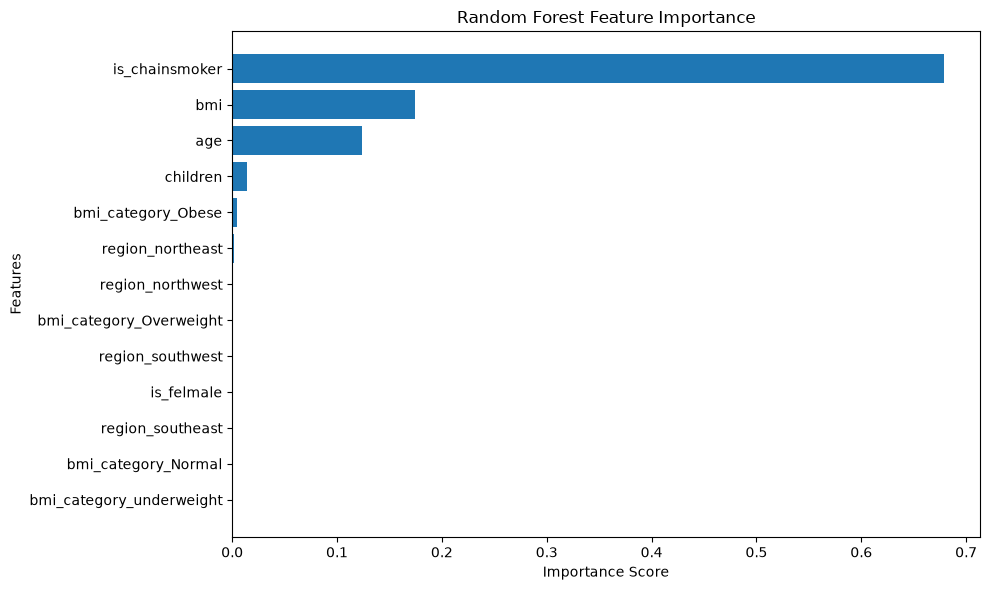

In [65]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_model.feature_importances_
})

# Sort from highest to lowest
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))
plt.barh(
    importance["Feature"],
    importance["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


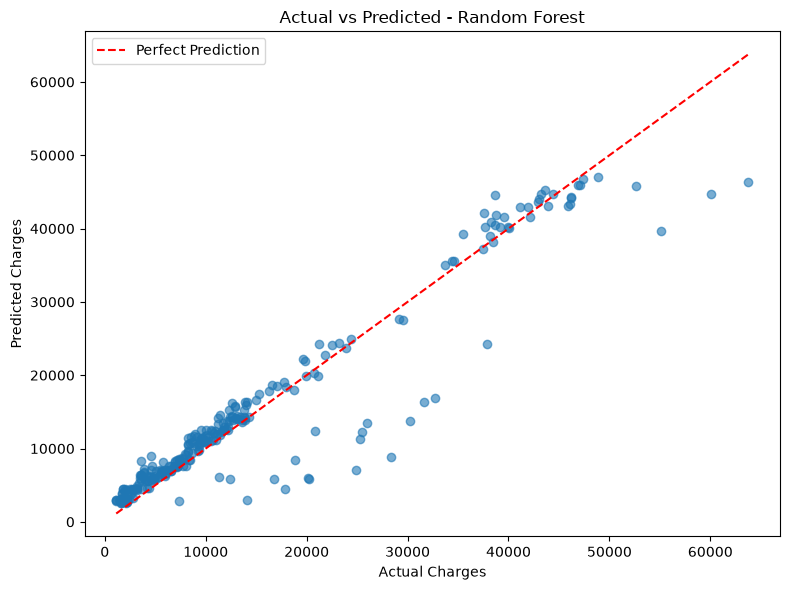

In [66]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_rf, alpha=0.6)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted - Random Forest")
plt.legend()
plt.tight_layout()
plt.show()



{Residual} = {Actual} -{Predicted}


           Actual     Predicted     Residual
900    8688.85885  10936.908679 -2248.049829
1064   5708.86700   6813.781455 -1104.914455
1256  11436.73815  11800.091309  -363.353159
298   38746.35510  41909.005615 -3162.650515
237    4463.20510   6064.466901 -1601.261801
481    9304.70190  10637.439075 -1332.737175
240   38511.62830  38183.146965   328.481335
277    2150.46900   2741.694828  -591.225828
415    7345.72660   8368.815420 -1023.088820
707   10264.44210  11609.588892 -1345.146792


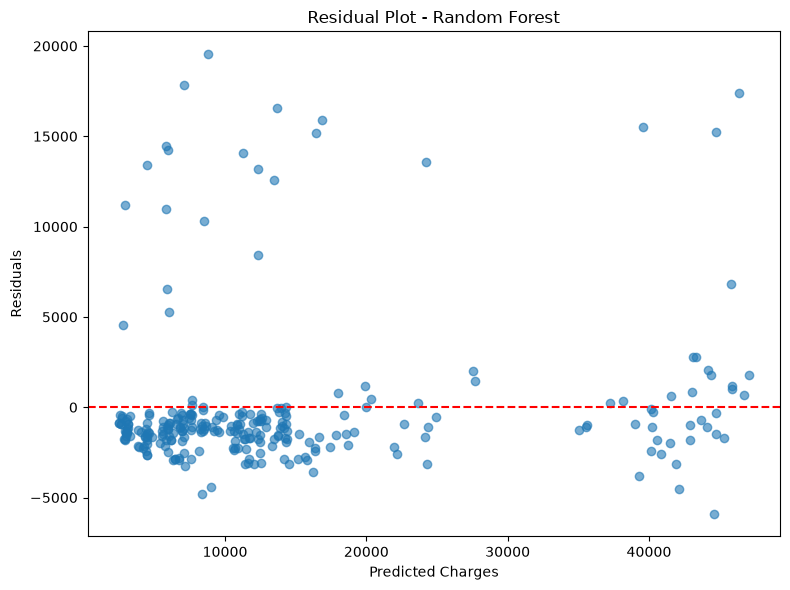

Mean Residual: -69.73664269186699
Mean Absolute Residual: 2423.236179906759


In [67]:

import pandas as pd
import matplotlib.pyplot as plt

# Create residual DataFrame
residuals_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_rf
})

residuals_df["Residual"] = (
    residuals_df["Actual"] -
    residuals_df["Predicted"]
)

print(residuals_df.head(10))

# Residual plot
plt.figure(figsize=(8, 6))

plt.scatter(
    residuals_df["Predicted"],
    residuals_df["Residual"],
    alpha=0.6
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.title("Residual Plot - Random Forest")
plt.tight_layout()
plt.show()

print("Mean Residual:", residuals_df["Residual"].mean())
print("Mean Absolute Residual:",
      residuals_df["Residual"].abs().mean())


In [70]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict using your tuned Random Forest
y_pred_rf = best_model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)

print("Final Model: Random Forest Regressor")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Final Model: Random Forest Regressor
MAE: 2423.236179906759
RMSE: 4243.985863163282
R2 Score: 0.9019819231505671


In [71]:
import joblib

joblib.dump(best_model, "best_random_forest.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [73]:
print("Model:", best_model)
print("Scaler fitted:", hasattr(
    StandardScaler(), "mean_"
))

Model: RandomForestRegressor(max_depth=5, min_samples_split=10, n_estimators=200,
                      random_state=42)
Scaler fitted: False


In [74]:
%whos

Variable                Type                          Data/Info
---------------------------------------------------------------
LinearRegression        ABCMeta                       <class 'sklearn.linear_mo<...>._base.LinearRegression'>
RandomForestRegressor   ABCMeta                       <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
RandomizedSearchCV      ABCMeta                       <class 'sklearn.model_sel<...>arch.RandomizedSearchCV'>
StandardScaler          type                          <class 'sklearn.preproces<...>ng._data.StandardScaler'>
X                       DataFrame                     Shape: (1337, 13)
X_test                  DataFrame                     Shape: (268, 13)
X_train                 DataFrame                     Shape: (1069, 13)
alpha                   float                         0.05
best_model              RandomForestRegressor         RandomForestRegressor(max<...>         random_state=42)
chi2                    float64                 

In [75]:
print("Training features:")
print(X_train.columns.tolist())

print("\nModel parameters:")
print(best_model.get_params())

Training features:
['age', 'is_felmale', 'bmi', 'children', 'is_chainsmoker', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_underweight', 'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese']

Model parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 5, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [76]:
import joblib

joblib.dump(best_model, "best_random_forest.pkl")

print("Final Random Forest model saved successfully!")

Final Random Forest model saved successfully!


In [78]:
import joblib

joblib.dump(best_model, "best_random_forest.pkl")

print("Model saved successfully!")

Model saved successfully!
